# Escenarios, credibilidad y el enfoque de medición estándar

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular con el motor el indicador de negocio, su componente y tramo, el componente de pérdidas, el multiplicador de pérdidas internas y el capital del enfoque de medición estándar (SMA), y verificar cada uno contra la fórmula y el valor de referencia del texto de Basilea;
- mostrar cómo una pérdida grande mueve el capital del SMA a través del multiplicador, y leer la prueba `oprisk.sma_ilm_response`;
- convertir escenarios de expertos en una cola: como pseudo-observaciones, como una cola ajustada y como una a priori Gamma actualizada con los datos de pérdida (credibilidad bayesiana);
- medir cuánto mueve cada escenario al capital, y leer la prueba `oprisk.scenario_influence`.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El generador del caso C17 y sus estimadores viven en `data-pipeline/pipeline/cases/c17/`, que no es un paquete instalado: este cuaderno carga esos módulos por su ruta (importar todo el paquete `pipeline` importaría todos los casos y sus dependencias pesadas). La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import distributions, scenarios, sma
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Todo del caso C17, variante con índice de cola 0,8, para el banco sintético de EUR 50 mil millones en activos.

- **Archivo que se lee:** `data/derived/C17/xi-0-8.json`: `outputs.bank` (el indicador de negocio que declara el caso), `outputs.sma_response` (el SMA tras agregar una pérdida grande a una historia), `outputs.scenario_influence` (los ocho escenarios de expertos y la influencia de cada uno en el capital) y las filas correspondientes de `tests`. `data/derived/C17/models-generator.json` guarda la especificación del SMA con su valor de referencia.
- **Historias:** el SMA lee pérdidas anuales, y los documentos versionados guardan resúmenes, no historias. Como en el cuaderno 02, el generador del caso se carga por su ruta y regenera la historia detrás de cada bloque versionado a partir de la semilla que el bloque registra.
- **Qué es sintético:** los tres años de partidas de ingreso y gasto del banco y los escenarios los inventa el caso; el banco sintético no se presenta como uno real.

La celda siguiente carga los documentos y el generador e imprime las semillas de los dos bloques.

In [2]:
# Cargar el documento de la variante y el documento del generador (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
LANG = "es"
variant_doc = json.loads((ROOT / "data" / "derived" / "C17" / "xi-0-8.json").read_text(encoding="utf-8"))
generator_doc = json.loads((ROOT / "data" / "derived" / "C17" / "models-generator.json").read_text(encoding="utf-8"))
bank = variant_doc["outputs"]["bank"]
response = variant_doc["outputs"]["sma_response"]
influence_block = variant_doc["outputs"]["scenario_influence"]
print("banco:", bank["label"][LANG])
print("semilla del bloque de respuesta del SMA:", response["seed"], response["cell_id"], "| semilla del bloque de escenarios:", influence_block["seed"], influence_block["cell_id"])

banco: Banco sintético de EUR 50 mil millones en activos
semilla del bloque de respuesta del SMA: 4208000 y10-h20000 | semilla del bloque de escenarios: 4208002 y10-h20000


El generador del caso se carga por su ruta, bajo un nombre de paquete desechable, para no importar nada más del pipeline; `sys.dont_write_bytecode` evita que la importación deje archivos de caché en el repositorio. Además del generador y las constantes del caso, el cuaderno usa dos funciones del propio `replicate.py` del caso que componen llamadas al motor para el peldaño de escenarios: `scenario_prior` (la elección de la semilla del bootstrap) y `scenario_capital`. La estimación misma es del motor.

In [3]:
# Cargar el generador, las constantes y los auxiliares de escenarios del caso desde data-pipeline/ por ruta
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, params as case_params, replicate

variant = generator.variant(0.8)
H = 20_000.0
print("índice de cola verdadero:", variant.tail_index, "| umbral de recolección (EUR):", int(H))

índice de cola verdadero: 0.8 | umbral de recolección (EUR): 20000


## Método

La parte A sigue el enfoque de medición estándar (SMA) del marco de Basilea, OPE25 (BCBS, Basel Framework): calcula un capital desde el tamaño del banco y su propia historia de pérdidas, sin distribución. La parte B convierte escenarios de expertos en una cola y mide su influencia. Ambas terminan en un capital que se puede poner junto al capital LDA de los cuadernos anteriores.

### A1: el indicador de negocio

El indicador de negocio es la suma de tres componentes construidos con las partidas de ingreso y gasto de los últimos tres años (OPE25.4 y OPE25.5): el componente de intereses, arriendos y dividendos, el de servicios y el financiero,

$$\mathrm{ILDC} = \min\big(\overline{|II - IE|},\; 0{,}0225\,\overline{IEA}\big) + \overline{DI}, \quad \mathrm{SC} = \max(\overline{OOI}, \overline{OOE}) + \max(\overline{FI}, \overline{FE}), \quad \mathrm{FC} = \overline{|PL_{TB}|} + \overline{|PL_{BB}|}$$

donde una barra es el promedio de tres años, con los valores absolutos de las partidas netas tomados año a año antes de promediar, y $\mathrm{BI} = \mathrm{ILDC} + \mathrm{SC} + \mathrm{FC}$. El caso declara los tres años de partidas del banco en `params.BANK`. La celda siguiente imprime los promedios que entran en cada fórmula, llama a las cuatro funciones del motor y compara el resultado con el documento.

In [4]:
# Los promedios dentro de cada fórmula, las cuatro funciones del motor, y el indicador de negocio del documento
items = {key: np.array(values, dtype=float) for key, values in case_params.BANK.items()}
print("media |II - IE| = %.3e | 0.0225 * media IEA = %.3e | media DI = %.3e" % (np.abs(items["ii"] - items["ie"]).mean(), 0.0225 * items["iea"].mean(), items["di"].mean()))
print("max(media OOI, media OOE) = %.3e | max(media FI, media FE) = %.3e" % (max(items["ooi"].mean(), items["ooe"].mean()), max(items["fi"].mean(), items["fe"].mean())))
print("media |PL_TB| = %.3e | media |PL_BB| = %.3e" % (np.abs(items["pl_tb"]).mean(), np.abs(items["pl_bb"]).mean()))
ildc = sma.ildc(items["ii"], items["ie"], items["iea"], items["di"])
service = sma.service_component(items["ooi"], items["ooe"], items["fi"], items["fe"])
financial = sma.financial_component(items["pl_tb"], items["pl_bb"])
bi = sma.business_indicator(ildc, service, financial)
print("ILDC = %.3e | SC = %.3e | FC = %.3e | BI = %.3e" % (ildc, service, financial, bi))
print("documento: ", {k: "%.3e" % v for k, v in bank["business_indicator"].items()})

media |II - IE| = 7.000e+08 | 0.0225 * media IEA = 1.012e+09 | media DI = 1.000e+08
max(media OOI, media OOE) = 1.000e+08 | max(media FI, media FE) = 4.000e+08
media |PL_TB| = 5.000e+07 | media |PL_BB| = 5.000e+07
ILDC = 8.000e+08 | SC = 5.000e+08 | FC = 1.000e+08 | BI = 1.400e+09
documento:  {'ildc_eur': '8.000e+08', 'sc_eur': '5.000e+08', 'fc_eur': '1.000e+08', 'bi_eur': '1.400e+09'}


### A2: el componente del indicador de negocio y el tramo

El componente es una escala de tasas marginales sobre el indicador, con 12% hasta EUR 1.000 millones, 15% de 1.000 a 30.000 millones y 18% sobre eso (OPE25.7, tabla 1), y el tramo es 1, 2 o 3 según los mismos límites:

$$\mathrm{BIC} = 0{,}12\,\min(\mathrm{BI}, 10^9) + 0{,}15\,\big(\min(\mathrm{BI}, 30\cdot10^9) - 10^9\big)^+ + 0{,}18\,\big(\mathrm{BI} - 30\cdot10^9\big)^+$$

El texto de Basilea da un valor de referencia: un indicador de EUR 35.000 millones tiene un componente de EUR 5.370 millones (OPE25.7, nota 2), que podemos sumar a mano: $0{,}12 \cdot 1 + 0{,}15 \cdot 29 + 0{,}18 \cdot 5 = 5{,}37$ mil millones. La celda siguiente verifica el valor de referencia con `bic`, y luego el componente y el tramo del banco.

In [5]:
# El valor dorado de OPE25.7 a mano y con el motor, y luego el componente y el tramo del banco
golden = generator_doc["fit"]["sma"]["golden"]
by_hand = 0.12 * 1e9 + 0.15 * 29e9 + 0.18 * 5e9
print("BI = %.1e | a mano %.4e | motor %.4e | valor de referencia del documento %.4e" % (golden["bi_eur"], by_hand, sma.bic(golden["bi_eur"]), golden["bic_eur"]))
bic_bank = sma.bic(bi)
print("banco: BI = %.2e | BIC = %.4e | tramo %d | documento: BIC = %.4e, tramo %d" % (bi, bic_bank, sma.bic_bucket(bi), bank["bic_eur"], bank["bucket"]))

BI = 3.5e+10 | a mano 5.3700e+09 | motor 5.3700e+09 | valor de referencia del documento 5.3700e+09
banco: BI = 1.40e+09 | BIC = 1.8000e+08 | tramo 2 | documento: BIC = 1.8000e+08, tramo 2


### A3: el componente de pérdidas y el multiplicador de pérdidas internas

Las pérdidas propias del banco entran por el componente de pérdidas, 15 veces la pérdida anual promedio de los últimos diez años, y el multiplicador lo compara con el componente del indicador de negocio (OPE25.8 y OPE25.9):

$$\mathrm{LC} = 15 \cdot \overline{L}_{10}, \qquad \mathrm{ILM} = \ln\!\Big(e - 1 + \big(\mathrm{LC}/\mathrm{BIC}\big)^{0{,}8}\Big), \qquad \mathrm{ORC} = \mathrm{BIC} \cdot \mathrm{ILM}$$

Cuando $\mathrm{LC} = \mathrm{BIC}$ el multiplicador es exactamente 1, y sobre eso el multiplicador supera 1. La celda siguiente regenera la historia detrás del bloque de respuesta versionado (semilla y celda del documento), registra las pérdidas sobre el umbral y calcula el componente de pérdidas, el multiplicador y `sma_capital`, que además aplica la regla de que con menos de cinco años de datos se usa solo el componente (OPE25.10 y OPE25.15). Compara con la primera fila del bloque versionado, calculado por una versión anterior del motor.

In [6]:
# Regenerar la historia del bloque de respuesta y calcular el SMA paso a paso
history = generator.draw_history(variant, response["seed"], 10).recorded(H)
annual = history.annual
lc = sma.loss_component(annual)
ilm_value = sma.ilm(lc, bic_bank)
result = sma.sma_capital(bi, annual)
first = response["rows"][0]
print("pérdida anual promedio (EUR): %.1f | LC = 15 x = %.1f | LC / BIC = %.4f" % (annual.mean(), lc, lc / bic_bank))
print("ILM = %.9f | ORC = %.1f | base %s | discreción %s" % (ilm_value, result.orc, result.basis, result.discretion_applied))
print("primera fila versionada: LC = %.1f | ILM = %.9f | ORC = %.1f" % (first["lc_eur"], first["ilm"], first["orc_eur"]))
print("ILM cuando LC = BIC:", sma.ilm(bic_bank, bic_bank))
short = sma.sma_capital(bi, annual[:4])
print("con 4 años de pérdidas: base %s | discreción %s | ORC = BIC = %.1f" % (short.basis, short.discretion_applied, short.orc))
print("calculado por riskvalidation", variant_doc["provenance"]["riskvalidation_version"], "| instalado", md.version("riskvalidation"))

pérdida anual promedio (EUR): 5005390.8 | LC = 15 x = 75080861.7 | LC / BIC = 0.4171
ILM = 0.795301641 | ORC = 143154295.3 | base bic-times-ilm | discreción none
primera fila versionada: LC = 75080861.7 | ILM = 0.795301641 | ORC = 143154295.0
ILM cuando LC = BIC: 1.0
con 4 años de pérdidas: base bic-only | discreción transitional-bic-only | ORC = BIC = 180000000.0
calculado por riskvalidation 0.7.0 | instalado 0.9.0


### A4: qué hace una pérdida grande al SMA

Como el componente de pérdidas promedia diez años, una sola pérdida grande lo mueve en una décima de quince veces su tamaño, y el multiplicador por la función cóncava de arriba. El caso agrega al último año una pérdida de 0, 0,1, 0,25, 0,5 y 1 veces el BIC, y registra el capital en cada caso. La prueba `oprisk.sma_ilm_response` resume el salto del multiplicador cuando se agrega una pérdida de la mitad del BIC: su métrica es el multiplicador después menos el multiplicador antes, y la luz es un umbral interno de Contraste (verde hasta 0,05, ámbar hasta 0,15, rojo sobre eso), no un umbral regulatorio. La celda siguiente recalcula las cinco filas con `sma_capital` y la prueba con el motor, y las compara con las versionadas.

In [7]:
# Agregar una pérdida grande al último año, recalcular el SMA, y correr la prueba de respuesta del ILM
print("%14s %16s %10s %16s | %s" % ("pérdida agregada", "LC", "ILM", "ORC", "ILM, ORC versionados"))
for row in response["rows"]:
    stressed = annual.copy()
    stressed[-1] += row["added_loss_eur"]
    r = sma.sma_capital(bi, stressed)
    print("%14s %16s %10.6f %16s | %.6f %s" % (format(row["added_loss_eur"], ",.0f"), format(r.loss_component, ",.0f"), r.ilm, format(r.orc, ",.0f"), row["ilm"], format(row["orc_eur"], ",.0f")))
test = oprisk_tests.sma_ilm_response(bank["bic_eur"], annual, 0.5 * bank["bic_eur"], model_id="sma")
committed_test = next(t for t in variant_doc["tests"] if t["test_id"] == "oprisk.sma_ilm_response")
print("prueba: salto del ILM %.6f (versionado %.6f) | luz %s (versionada %s) | umbrales %s"
      % (test.metric, committed_test["metric"], test.light.value, committed_test["light"], test.extras["thresholds"]))

pérdida agregada               LC        ILM              ORC | ILM, ORC versionados
             0       75,080,862   0.795302      143,154,295 | 0.795302 143,154,295
    18,000,000      102,080,862   0.855913      154,064,272 | 0.855913 154,064,272
    45,000,000      142,580,862   0.935384      168,369,122 | 0.935384 168,369,122
    90,000,000      210,080,862   1.047276      188,509,667 | 1.047276 188,509,667
   180,000,000      345,080,862   1.224192      220,354,518 | 1.224192 220,354,518
prueba: salto del ILM 0.251974 (versionado 0.251974) | luz red (versionada red) | umbrales {'jump_green': 0.05, 'jump_amber': 0.15}


### B1: los escenarios de expertos

Un experto da escenarios como pares de una pérdida y la frecuencia con que ocurre una pérdida al menos de ese tamaño. El caso declara ocho para el banco sintético, redondeados a dos cifras significativas como lo haría un experto, desde "una pérdida de EUR 190.000 cuatro veces al año" hasta "EUR 1,3 millones una vez cada dos años y medio"; dos de ellos se rotulan como eventos nombrados. El motor representa cada uno como un `ScenarioPoint` con su tipo, pérdida y frecuencia de excedencia por año. La celda siguiente construye los puntos desde el bloque versionado y los imprime con su rótulo en el idioma del cuaderno.

In [8]:
# Construir los puntos de escenario del motor desde el bloque versionado
points = [scenarios.ScenarioPoint(s["scenario_id"], s["kind"], s["loss_eur"], s["exceedance_frequency_per_year"]) for s in influence_block["scenarios"]]
KIND = {"percentile": "percentil", "individual": "individual"}
for s, p in zip(influence_block["scenarios"], points):
    print("%-3s %-10s EUR %10s | %5.2f al año | %s" % (p.scenario_id, KIND[p.kind], format(p.loss, ",.0f"), p.exceedance_frequency, s["label"][LANG]))
rebuilt = replicate.scenario_points(variant)
print("la construcción del propio caso da los mismos puntos:", ("sí" if all(a.loss == b.loss and a.exceedance_frequency == b.exceedance_frequency for a, b in zip(points, rebuilt)) else "no"))

S1  percentil  EUR    190,000 |  4.00 al año | Pérdida cuatro veces al año
S2  percentil  EUR    250,000 |  3.00 al año | Pérdida tres veces al año
S3  percentil  EUR    350,000 |  2.00 al año | Pérdida dos veces al año
S4  percentil  EUR    440,000 |  1.50 al año | Pérdida tres veces cada dos años
S5  percentil  EUR    620,000 |  1.00 al año | Pérdida una vez al año
S6  individual EUR    780,000 |  0.75 al año | Evento nombrado: caída de la plataforma central
S7  percentil  EUR  1,100,000 |  0.50 al año | Pérdida una vez cada dos años
S8  individual EUR  1,300,000 |  0.40 al año | Evento nombrado: fraude externo grande
la construcción del propio caso da los mismos puntos: sí


### B2: escenarios como pseudo-observaciones, y como cola ajustada

Dos formas simples de usar escenarios. Como **pseudo-observaciones**, cada escenario es una pérdida que aparece en los datos $\text{frecuencia} \times \text{años}$ veces, lo que `scenario_pseudo_observations` devuelve como pérdidas y pesos. Como **cola ajustada**, cada punto implica la probabilidad condicional de superar su pérdida dado que hay una pérdida sobre el umbral de la cola $u_s$, $\text{frecuencia}_j / f_{u_s}$, donde $f_{u_s}$ es la frecuencia que da el experto de pérdidas sobre $u_s$; se ajusta una Pareto generalizada por mínimos cuadrados sobre los logaritmos de los excesos, como en el cuaderno 02, con `fit_tail_to_scenarios`:

$$\min_{\xi,\beta}\; \sum_j \left[\ln\!\Big(\tfrac{\beta}{\xi}\big(c_j^{-\xi} - 1\big)\Big) - \ln(\ell_j - u_s)\right]^2, \qquad c_j = \frac{\text{frecuencia}_j}{f_{u_s}}$$

donde $\ell_j$ es la pérdida del escenario. El caso usa $u_s$ = EUR 100.000 y $f_{u_s}$ = el número esperado verdadero de pérdidas sobre él, redondeado a dos cifras. La celda siguiente imprime las pseudo-observaciones para diez años y la cola ajustada.

In [9]:
# Pseudoobservaciones para diez años, y la Pareto generalizada ajustada a los puntos de escenario
U_S = case_params.SPLICE_THRESHOLD_EUR
f_above = replicate.expert_frequency_above_tail(variant)
losses_s, weights_s = scenarios.scenario_pseudo_observations(points, 10.0)
print("pseudo-observaciones (pérdida: peso):", {int(l): float(w) for l, w in zip(losses_s, weights_s)})
tail_fit = scenarios.fit_tail_to_scenarios(points, U_S, f_above)
print("frecuencia del experto sobre EUR", int(U_S), ":", f_above)
print("xi = %.4f (se %.4f) | beta = %.1f (se %.1f) | convergió %s | xi verdadero %.2f" % (tail_fit.params[0], tail_fit.std_errors[0], tail_fit.params[1], tail_fit.std_errors[1], "sí" if tail_fit.converged else "no", variant.tail_index))

pseudo-observaciones (pérdida: peso): {190000: 40.0, 250000: 30.0, 350000: 20.0, 440000: 15.0, 620000: 10.0, 780000: 7.5, 1100000: 5.0, 1300000: 4.0}
frecuencia del experto sobre EUR 100000 : 8.6
xi = 0.8206 (se 0.0120) | beta = 87483.6 (se 1446.1) | convergió sí | xi verdadero 0.80


### B3: credibilidad bayesiana

El tercer método trata los escenarios como una **a priori** sobre la cola y deja que los datos de pérdida la actualicen (Shevchenko y Wuthrich, 2006). Para la Pareto de un parámetro sobre $L$, $f(x \mid \alpha) = (\alpha/L)(x/L)^{-\alpha-1}$ con forma $\alpha = 1/\xi$, una a priori Gamma sobre $\alpha$ con forma $a$ y tasa $r$ se actualiza, tras $n$ pérdidas $x_i \ge L$, a una a posteriori Gamma (Shevchenko y Wuthrich, 2006, sección 3.3):

$$\alpha \mid x \sim \mathrm{Gamma}\big(a + n,\; r + S\big), \quad S = \sum_{i=1}^{n} \ln(x_i/L), \qquad \hat\alpha = w\,\hat\alpha_{\mathrm{MLE}} + (1 - w)\,\frac{a}{r}, \quad w = \frac{S}{S + r}, \quad \hat\alpha_{\mathrm{MLE}} = \frac{n}{S}$$

La media a posteriori es una ponderación de **credibilidad** de la estimación de los datos y la media del experto: cuanto más dicen los datos ($S$ grande frente a $r$), más cerca de los datos. La a priori se construye desde el ajuste de los escenarios: su media es el $1/\xi_s$ de B2 y su intervalo de 90% sale de un bootstrap paramétrico de las frecuencias de los escenarios; el `scenario_prior` del caso toma la primera semilla del bootstrap cuyos reajustes quedan todos dentro de los límites de búsqueda del motor. La a priori no se restringe a $\alpha > 1$, así que un índice de cola de 1 o más sigue siendo posible. La celda siguiente imprime la a priori, cada término de la actualización con las unas 91 pérdidas de cola de la historia, y la identidad de la ponderación de credibilidad.

In [10]:
# La a priori desde los escenarios, la actualización con las pérdidas de cola de la historia, y la identidad de credibilidad
prior, bootstrap_seed = replicate.scenario_prior(variant, points, 10)
scenario_history = generator.draw_history(variant, influence_block["seed"], 10).recorded(H)
tail_losses = scenario_history.amounts[scenario_history.amounts >= U_S]
credibility = scenarios.credibility_pareto(prior, tail_losses, U_S)
s_total = float(np.log(tail_losses / U_S).sum())
print("a priori: forma, tasa, media de alpha, intervalo de 90%%: %.3f, %.3f, %.4f, (%.3f, %.3f) | semilla del bootstrap %d" % (prior.shape, prior.rate, prior.mean, prior.interval[0], prior.interval[1], bootstrap_seed))
print("n = %d | S = %.4f | a posteriori: forma, tasa: %.3f, %.4f" % (credibility.n, s_total, credibility.posterior_shape, credibility.posterior_rate))
print("alpha_MLE = n / S = %.4f | w = S / (S + r) = %.4f" % (credibility.n / s_total, s_total / (s_total + prior.rate)))
print("w * alpha_MLE + (1 - w) * a / r = %.6f | media a posteriori = %.6f" % (credibility.credibility_weight * credibility.alpha_mle + (1 - credibility.credibility_weight) * prior.mean, credibility.alpha_mean))
print("xi = 1 / alpha = %.4f | beta = xi * L = %.1f | media infinita %s | xi verdadero %.2f" % (credibility.xi, credibility.beta, "sí" if credibility.infinite_mean else "no", variant.tail_index))

a priori: forma, tasa, media de alpha, intervalo de 90%: 54.104, 44.397, 1.2186, (1.012, 4.418) | semilla del bootstrap 0
n = 91 | S = 79.6431 | a posteriori: forma, tasa: 145.104, 124.0403
alpha_MLE = n / S = 1.1426 | w = S / (S + r) = 0.6421
w * alpha_MLE + (1 - w) * a / r = 1.169809 | media a posteriori = 1.169809
xi = 1 / alpha = 0.8548 | beta = xi * L = 85484.0 | media infinita no | xi verdadero 0.80


### B4: el capital que dan los escenarios, y la influencia de cada escenario

El peldaño de escenarios del caso toma el empalme del cuaderno 02 (cuerpo lognormal, cola sobre EUR 100.000) y reemplaza su cola Pareto por la cola de credibilidad, y luego agrega con la recursión de Panjer (cuaderno 03). La influencia del escenario $i$ es el cambio relativo del capital de 99,9% cuando se quita el escenario y se reconstruye la a priori con los restantes (la a priori es del experto, así que se mueve con ellos):

$$I_i = \frac{C_{\text{todos}} - C_{\text{sin } i}}{C_{\text{todos}}}$$

`scenario_influence` llama a la función de capital una vez con todos los escenarios y una vez por cada omisión. La prueba `oprisk.scenario_influence` toma la mayor influencia absoluta y la colorea frente a un umbral interno (verde hasta 0,10, ámbar hasta 0,25, rojo sobre eso). La celda siguiente calcula el capital con los escenarios y el capital solo con el empalme de la misma historia para contrastar, luego las ocho influencias (unos dos segundos), y corre la prueba. El bloque versionado está sobre la misma historia.

In [11]:
# El capital con los escenarios, el capital solo con empalme, las ocho influencias, y la prueba
lam_hat = distributions.fit_frequency(scenario_history.counts).params[0]
splice = distributions.fit_splice(scenario_history.amounts, H, U_S)
capital_with = replicate.scenario_capital(scenario_history, lam_hat, splice, prior)
cache = {}


def capital_without(subset):
    # el capital del peldaño de escenarios para un subconjunto de los puntos (la a priori se reconstruye desde ellos)
    key = tuple(p.scenario_id for p in subset)
    if key not in cache:
        cache[key] = replicate.scenario_capital(scenario_history, lam_hat, splice, replicate.scenario_prior(variant, list(subset), 10)[0])
    return cache[key]


influences = scenarios.scenario_influence(points, capital_without)
print("capital con los escenarios (EUR): %s | versionado %s" % (format(capital_with, ",.0f"), format(influence_block["base_capital_eur"], ",.0f")))
print("cuantil verdadero de 99.9% (EUR):", format(variant_doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"], ",.0f"))
for s, i in zip(influence_block["scenarios"], influences):
    print("%-3s influencia %+.4f | versionada %+.4f" % (s["scenario_id"], i, s["influence"]))
influence_test = oprisk_tests.scenario_influence(influences, model_id="scenario")
print("prueba: mayor influencia absoluta %.4f | luz %s | umbrales %s" % (influence_test.metric, influence_test.light.value, influence_test.extras["thresholds"]))

capital con los escenarios (EUR): 247,029,041 | versionado 247,029,041
cuantil verdadero de 99.9% (EUR): 163,483,000
S1  influencia +0.0828 | versionada +0.0828
S2  influencia +0.0081 | versionada +0.0081
S3  influencia -0.0390 | versionada -0.0390
S4  influencia -0.0397 | versionada -0.0397
S5  influencia -0.0318 | versionada -0.0318
S6  influencia -0.0137 | versionada -0.0137
S7  influencia -0.0317 | versionada -0.0317
S8  influencia -0.0653 | versionada -0.0653
prueba: mayor influencia absoluta 0.0828 | luz green | umbrales {'influence_amber': 0.1, 'influence_red': 0.25}


La última celda dibuja las lecciones. A la izquierda, el capital del SMA tras agregar una pérdida al último año, frente al capital de la aproximación de pérdida única de la misma historia que el caso guarda a su lado: el SMA sube de forma suave, con el multiplicador cóncavo, mientras el capital basado en la distribución reacciona a la nueva pérdida en la cola. A la derecha, la influencia de cada escenario en el capital: la mayor, S1, lo mueve 8%, y los demás lo mueven menos, la mayoría hacia abajo.

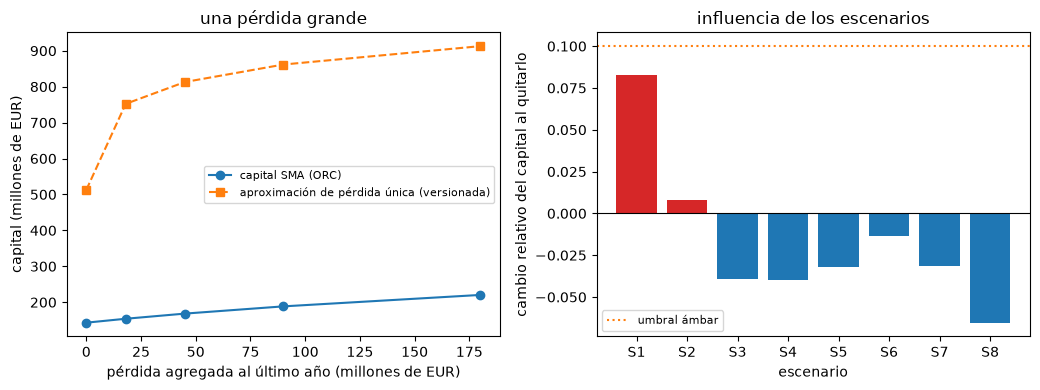

In [12]:
# Dibujar la respuesta del SMA contra la del LDA, y la influencia de cada escenario
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
added = np.array([row["added_loss_eur"] for row in response["rows"]]) / 1e6
left.plot(added, [row["orc_eur"] / 1e6 for row in response["rows"]], "o-", label="capital SMA (ORC)")
left.plot(added, [row["lda_capital_eur"] / 1e6 for row in response["rows"]], "s--", label="aproximación de pérdida única (versionada)")
left.set_xlabel("pérdida agregada al último año (millones de EUR)")
left.set_ylabel("capital (millones de EUR)")
left.set_title("una pérdida grande")
left.legend(fontsize=8)

right.bar([s["scenario_id"] for s in influence_block["scenarios"]], influences, color=["tab:red" if i > 0 else "tab:blue" for i in influences])
right.axhline(0.0, color="black", linewidth=0.8)
right.axhline(0.10, color="tab:orange", linestyle=":", label="umbral ámbar")
right.set_xlabel("escenario")
right.set_ylabel("cambio relativo del capital al quitarlo")
right.set_title("influencia de los escenarios")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **El indicador de negocio.** Los promedios dentro de las fórmulas dan un componente de intereses, arriendos y dividendos de EUR 800 millones, uno de servicios de EUR 500 millones y uno financiero de EUR 100 millones, un indicador de EUR 1,4 mil millones igual al del documento. El componente es de EUR 180 millones (tramo 2). El valor de referencia del texto de Basilea se reproduce a mano y con el motor: un indicador de EUR 35 mil millones da EUR 5,37 mil millones.
- **El componente de pérdidas y el multiplicador.** La historia regenerada tiene una pérdida anual promedio de EUR 5,0 millones, un componente de pérdidas de EUR 75,08 millones, 0,417 veces el componente del indicador, y por eso un multiplicador de 0,7953, bajo 1, y un capital de EUR 143,15 millones, igual a la fila versionada hasta el redondeo del archivo. Con 4 años de pérdidas el motor devuelve solo el componente, EUR 180 millones, con la discreción `transitional-bic-only`.
- **Una pérdida grande.** Agregar EUR 18, 45, 90 y 180 millones al último año mueve el multiplicador a 0,856, 0,935, 1,047 y 1,224 y el capital a EUR 154,1, 168,4, 188,5 y 220,4 millones, con cada fila igual a la versionada. La mitad del componente (EUR 90 millones) hace saltar el multiplicador en 0,252, y `oprisk.sma_ilm_response` queda roja frente a su umbral interno de 0,15. El capital versionado de la aproximación de pérdida única de la misma historia sube de EUR 512,7 millones a EUR 912,8 millones con las mismas adiciones.
- **Los escenarios como cola.** Los ocho escenarios ajustados por mínimos cuadrados dan un índice de cola de 0,8206 (error estándar 0,012) y una escala de EUR 87.484, frente a un índice de cola verdadero de 0,80; como pseudo-observaciones pesan de 40 a 4 eventos en diez años.
- **Credibilidad.** La a priori sobre la forma de la Pareto tiene media 1,2186, un índice de cola cercano a 0,82, con un intervalo de 90% de 1,012 a 4,418. Las 91 pérdidas sobre EUR 100.000 tienen $S$ = 79,64 y una estimación solo con los datos de 1,1426; el peso de credibilidad es 0,642, y la media a posteriori 1,1698 es igual al promedio ponderado de la estimación de los datos y la media a priori hasta seis decimales. El índice de cola actualizado es 0,8548, aún con media finita.
- **El capital y las influencias.** El capital con los escenarios es EUR 247,03 millones, igual al bloque versionado, 1,51 veces el cuantil verdadero de EUR 163,48 millones. La influencia de cada escenario está entre -6,5% (S8) y +8,3% (S1), los valores versionados con cuatro decimales, y `oprisk.scenario_influence` es verde con su mayor influencia absoluta de 0,0828 frente al umbral ámbar de 0,10.
- **Qué motor.** Los documentos versionados los calculó riskvalidation 0.7.0 y cada recálculo de aquí, con la 0.8.1, es igual a ellos en los dígitos impresos.

Lo que este cuaderno no muestra: cuán estable es el capital de cada método entre historias (cuaderno 06 y el cuaderno de nivel 4), ni cómo se compara el SMA con el LDA entre índices de cola (cuaderno 07).

## Resumen

- El SMA es una fórmula: el indicador de negocio da el componente por tramos, el promedio de diez años de pérdidas da el componente de pérdidas, y un multiplicador cóncavo los une; el motor reproduce el valor de referencia de Basilea.
- Una pérdida grande mueve el SMA de forma suave a través del multiplicador; el umbral interno sobre el salto del multiplicador es propio de Contraste y marca como roja una pérdida de la mitad del componente.
- Los escenarios pueden entrar a un modelo de cola como pseudo-observaciones, como cola ajustada o como a priori Gamma; la media a posteriori de credibilidad es exactamente un promedio ponderado de la estimación de los datos y la media del experto.
- La influencia de cada escenario en el capital es medible, y aquí la mayor es 8,3%.

**Qué probar a continuación.** Quita juntos los escenarios S1 y S8 y reconstruye la a priori con los otros seis para ver moverse el capital. Agrega una pérdida de dos veces el componente a la historia del SMA y mira cómo el multiplicador pasa de 1,3. Sigue con el cuaderno 06.

## Referencias

- BCBS, Basel Framework OPE25, Calculation of RWA for operational risk (el enfoque estándar), en vigor desde 2023-01-01. https://www.bis.org/basel_framework/chapter/OPE/25.htm
- Shevchenko, P. V. y Wuthrich, M. V. (2006), The structural modeling of operational risk via Bayesian inference: combining loss data with expert opinions, Journal of Operational Risk 1(3), 3-26. https://doi.org/10.21314/JOP.2006.016